# Lab 8 — Building a Graph from Agency Documents

**AI for Mobility · Module 3, section 3.1 (real graphs are often implicit) and the handout *Who Builds the Transportation Graph?***

After a hurricane, the links that decide which signals stay dark and which lift stations stop are not stored
anywhere as a table of node pairs. They are written in procedures and reports. In this lab you turn two real
agency documents into a graph:

- **FDOT District 7, *Traffic Signals Standard Operating Procedures (SOP) Reference Guide*, June 2025** (39 pages).
  The plan: who does what, in which phase, with which system.
- **Sarasota County, *2024 Hurricane Season After-Action Report (AAR)*, May 2025** (54 pages).
  What happened in Debby, Helene and Milton: which links worked, which failed, which were missing.

**What you will build.** A typed graph in which every edge carries a relation, a modality (required,
recommended, observed, failed), a page, and the exact quote that supports it. You will get edges three ways: from
a table, from a co-occurrence baseline, and from a language model given a fixed schema. Then you check them.

**What it proves.** *Structure is cheap and prose is expensive.* A table already is an edge list, and a few
lines of careful parsing turn it into one. Prose needs a model, and a model's edges are only worth keeping after
three checks: the quote is on the page, the entities are known, and a labeled sample agrees.

**Check it against.** A labeled gold set of 67 edges on four pages, and a co-occurrence baseline that joins
every pair of entities named in the same step or sentence. The question is not "did the model find edges?" but
"did it find more of the right ones than the baseline, and fewer wrong ones?"

*Runtime under a minute on a laptop. No GPU. No API key: the language-model output is shipped with the lab, and
section 6 shows you how to make your own with your Claude account.*

**Files.** The first code cell downloads the lab's files from the course site (about 4 MB): the AAR, the text of
the ten SOP pages this lab reads, the entity table, the schema, the prompts, the two model runs and the gold set.
The SOP itself is not posted. If you have the PDF from Canvas, put it in a folder called `data/` next to this
notebook and the lab will read it directly; the results are the same.

Reads with {doc}`3.1 Graphs everywhere in transportation <notes1-graph-data>` and the Module 3 handout *Who Builds
the Transportation Graph?*

## 0 · Setup

`pdfplumber` reads the PDFs, `networkx` holds the graph, `pandas` and `matplotlib` show the results. The cell
installs anything missing into the kernel you are running. If it installs something, restart the kernel once
(Colab: Runtime → Restart session; Jupyter: Kernel → Restart) and run it again.

In [1]:
import sys, subprocess, importlib, re, json, csv, hashlib, unicodedata, itertools, collections, zipfile
from pathlib import Path

def ensure(pkg):
    try:
        importlib.import_module(pkg)
    except ImportError:
        try:
            ip = get_ipython()
        except NameError:
            ip = None
        if ip is not None:
            ip.run_line_magic("pip", f"install -q {pkg}")
        else:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for pkg in ["pdfplumber", "networkx", "pandas", "matplotlib"]:
    ensure(pkg)

import pdfplumber, networkx as nx, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

LAB = Path.cwd()
FILES = LAB / "lab8_files"
DATA = LAB / "data"
FILES_URL = "https://ai4mobility.github.io/_static/data/lab8_agency_graph_files.zip"

if not FILES.exists():
    import urllib.request
    zip_path = LAB / "lab8_agency_graph_files.zip"
    print(f"downloading {FILES_URL} ...")
    urllib.request.urlretrieve(FILES_URL, zip_path)
    zipfile.ZipFile(zip_path).extractall(LAB)       # creates lab8_files/ and data/

def find_pdf(keywords):
    for p in sorted(DATA.glob("*.pdf")) + sorted(LAB.glob("*.pdf")):
        if any(k in p.name.lower() for k in keywords):
            return p
    return None

SOP_PDF = find_pdf(["sop", "standard_operating"])        # optional: from Canvas
AAR_PDF = find_pdf(["aar", "after-action", "after_action"])
assert AAR_PDF is not None, f"The AAR PDF should be in {DATA} after the download."
print("SOP:", SOP_PDF.name if SOP_PDF else "text of 10 pages from lab8_files/sop_pages.json (no PDF needed)")
print("AAR:", AAR_PDF.name)

SOP: text of 10 pages from lab8_files/sop_pages.json (no PDF needed)
AAR: Sarasota_County_2024_Hurricane_AAR.pdf


### Reading the pages

Every check in this lab compares strings, so the text of a page must be read the same way every time. `norm()`
makes two quotes compare equal when they differ only in curly versus straight quotes, dashes, line breaks or
case. The language model saw page text read by exactly this code.

In [2]:
_SUB = {"\u2019": "'", "\u2018": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-",
        "\u00a0": " ", "\u2044": "/"}

def light(s):
    """Same characters for the same text: quotes, dashes, line breaks and spaces made uniform."""
    s = unicodedata.normalize("NFKC", s)
    for a, b in _SUB.items():
        s = s.replace(a, b)
    s = re.sub(r"-\s*\n\s*", "-", s)      # a hyphen at the end of a line
    return re.sub(r"\s+", " ", s).strip()

def norm(s):
    return light(s).lower()

PAGES = {}                                 # (doc, page) -> raw text
with pdfplumber.open(AAR_PDF) as pdf:
    for i, page in enumerate(pdf.pages, start=1):
        PAGES[("AAR", i)] = page.extract_text() or ""
SOP_TEXT = json.loads((FILES / "sop_pages.json").read_text(encoding="utf-8"))
if SOP_PDF:
    with pdfplumber.open(SOP_PDF) as pdf:
        for p in map(int, SOP_TEXT["pages"]):
            PAGES[("SOP", p)] = pdf.pages[p - 1].extract_text() or ""
else:
    for p, text in SOP_TEXT["pages"].items():
        PAGES[("SOP", int(p))] = text
NPAGES = {k: norm(v) for k, v in PAGES.items()}

for doc in ["SOP", "AAR"]:
    pages = sorted(p for d, p in PAGES if d == doc)
    words = sum(len(PAGES[(doc, p)].split()) for p in pages)
    print(f"{doc}: {len(pages)} pages read ({pages[0]}-{pages[-1]}), {words:,} words")

SOP: 10 pages read (4-25), 2,354 words
AAR: 54 pages read (1-54), 14,813 words


## 1 · Look at the documents before you parse them

Two pages, two very different shapes. The SOP's post-storm steps are numbered, nested and grouped by phase.
The AAR's Enhancements Matrix is a table with a lead and a supporting organization for every recommendation.

SOP, PDF page 8 (first 14 lines): numbered steps by phase

Post-Storm Procedures
Immediately Post Storm
1. Use ATMS signal system to determine what corridors are functional, meaning the signal is actively
communicating with the ATMS signal system.
1.1. If a signal is functioning within the ATMS signal system, the signal symbol will appear green.
1.1.1. This indicates the signal is actively communicating and operational.
1.1.2. All operational (green) signals in the ATMS signal system should be fully reflected in
eSTORM.
1.2. Signals shown as yellow or red, meaning a signal is in flash or non-operational, respectively, and
should be evaluated for further action.
1.2.1. A yellow or red status in the ATMS signal system should be used to help prioritize SAT
and generator deployment teams.
2. Conduct an initial windshield survey of corridors. Utilize SATs and Local Agency input.
2.1. SAT deployment teams to conduct the initial pass of all roadways immediately post storm,


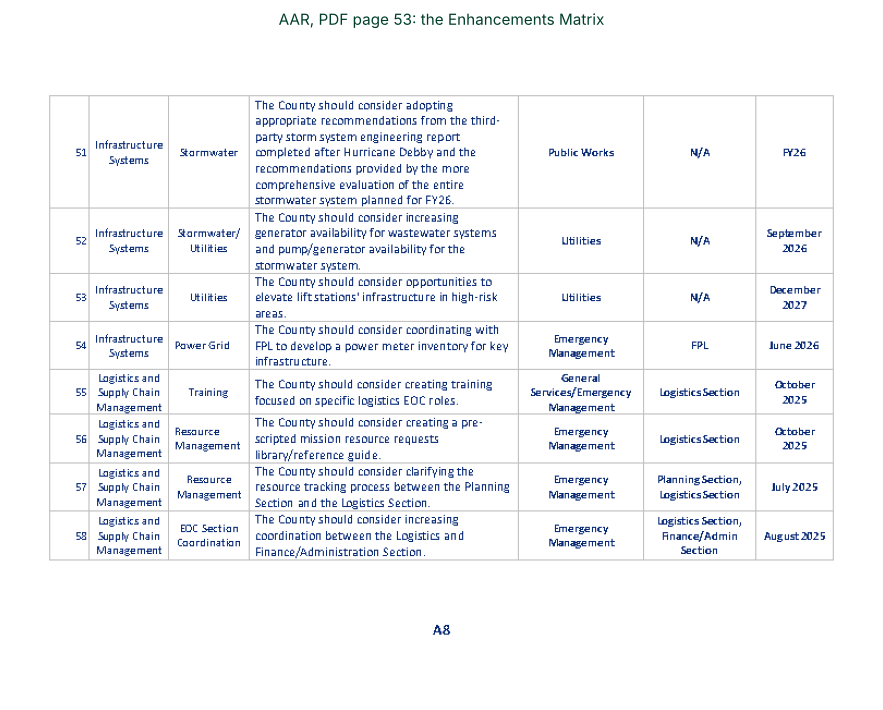

In [3]:
print("SOP, PDF page 8 (first 14 lines): numbered steps by phase\n")
print("\n".join(PAGES[("SOP", 8)].splitlines()[:14]))

with pdfplumber.open(AAR_PDF) as pdf:
    img = pdf.pages[53 - 1].to_image(resolution=72).original
fig, ax = plt.subplots(figsize=(10, 7.2))
ax.imshow(img); ax.axis("off")
ax.set_title("AAR, PDF page 53: the Enhancements Matrix", fontsize=11, color="#003E2A")
plt.tight_layout(); plt.show()

**Look for two things.** The SOP's steps have no actor in most sentences ("Conduct an initial windshield
survey"), so the document's owner, District 7, is the implied subject. The AAR's matrix has a column for the lead
organization and one for supporters, so its edges are already there; you only have to read them correctly.

One more thing you cannot see in the picture: in this copy of the SOP, **Appendix B (zone maps) and Appendix C
(responsibility matrix) are blank pages**. The most graph-like part of the SOP is missing, so its edges have to
come from the prose.

In [4]:
for p in [24, 25]:
    print(f"SOP page {p}: {PAGES[('SOP', p)].strip()!r}")

SOP page 24: 'Appendix B:Hurricane Response Zone Maps'
SOP page 25: 'Appendix C: Responsbility Matrix'


## 2 · Decide the schema before you extract anything

The whole lab in one picture, before any more code.

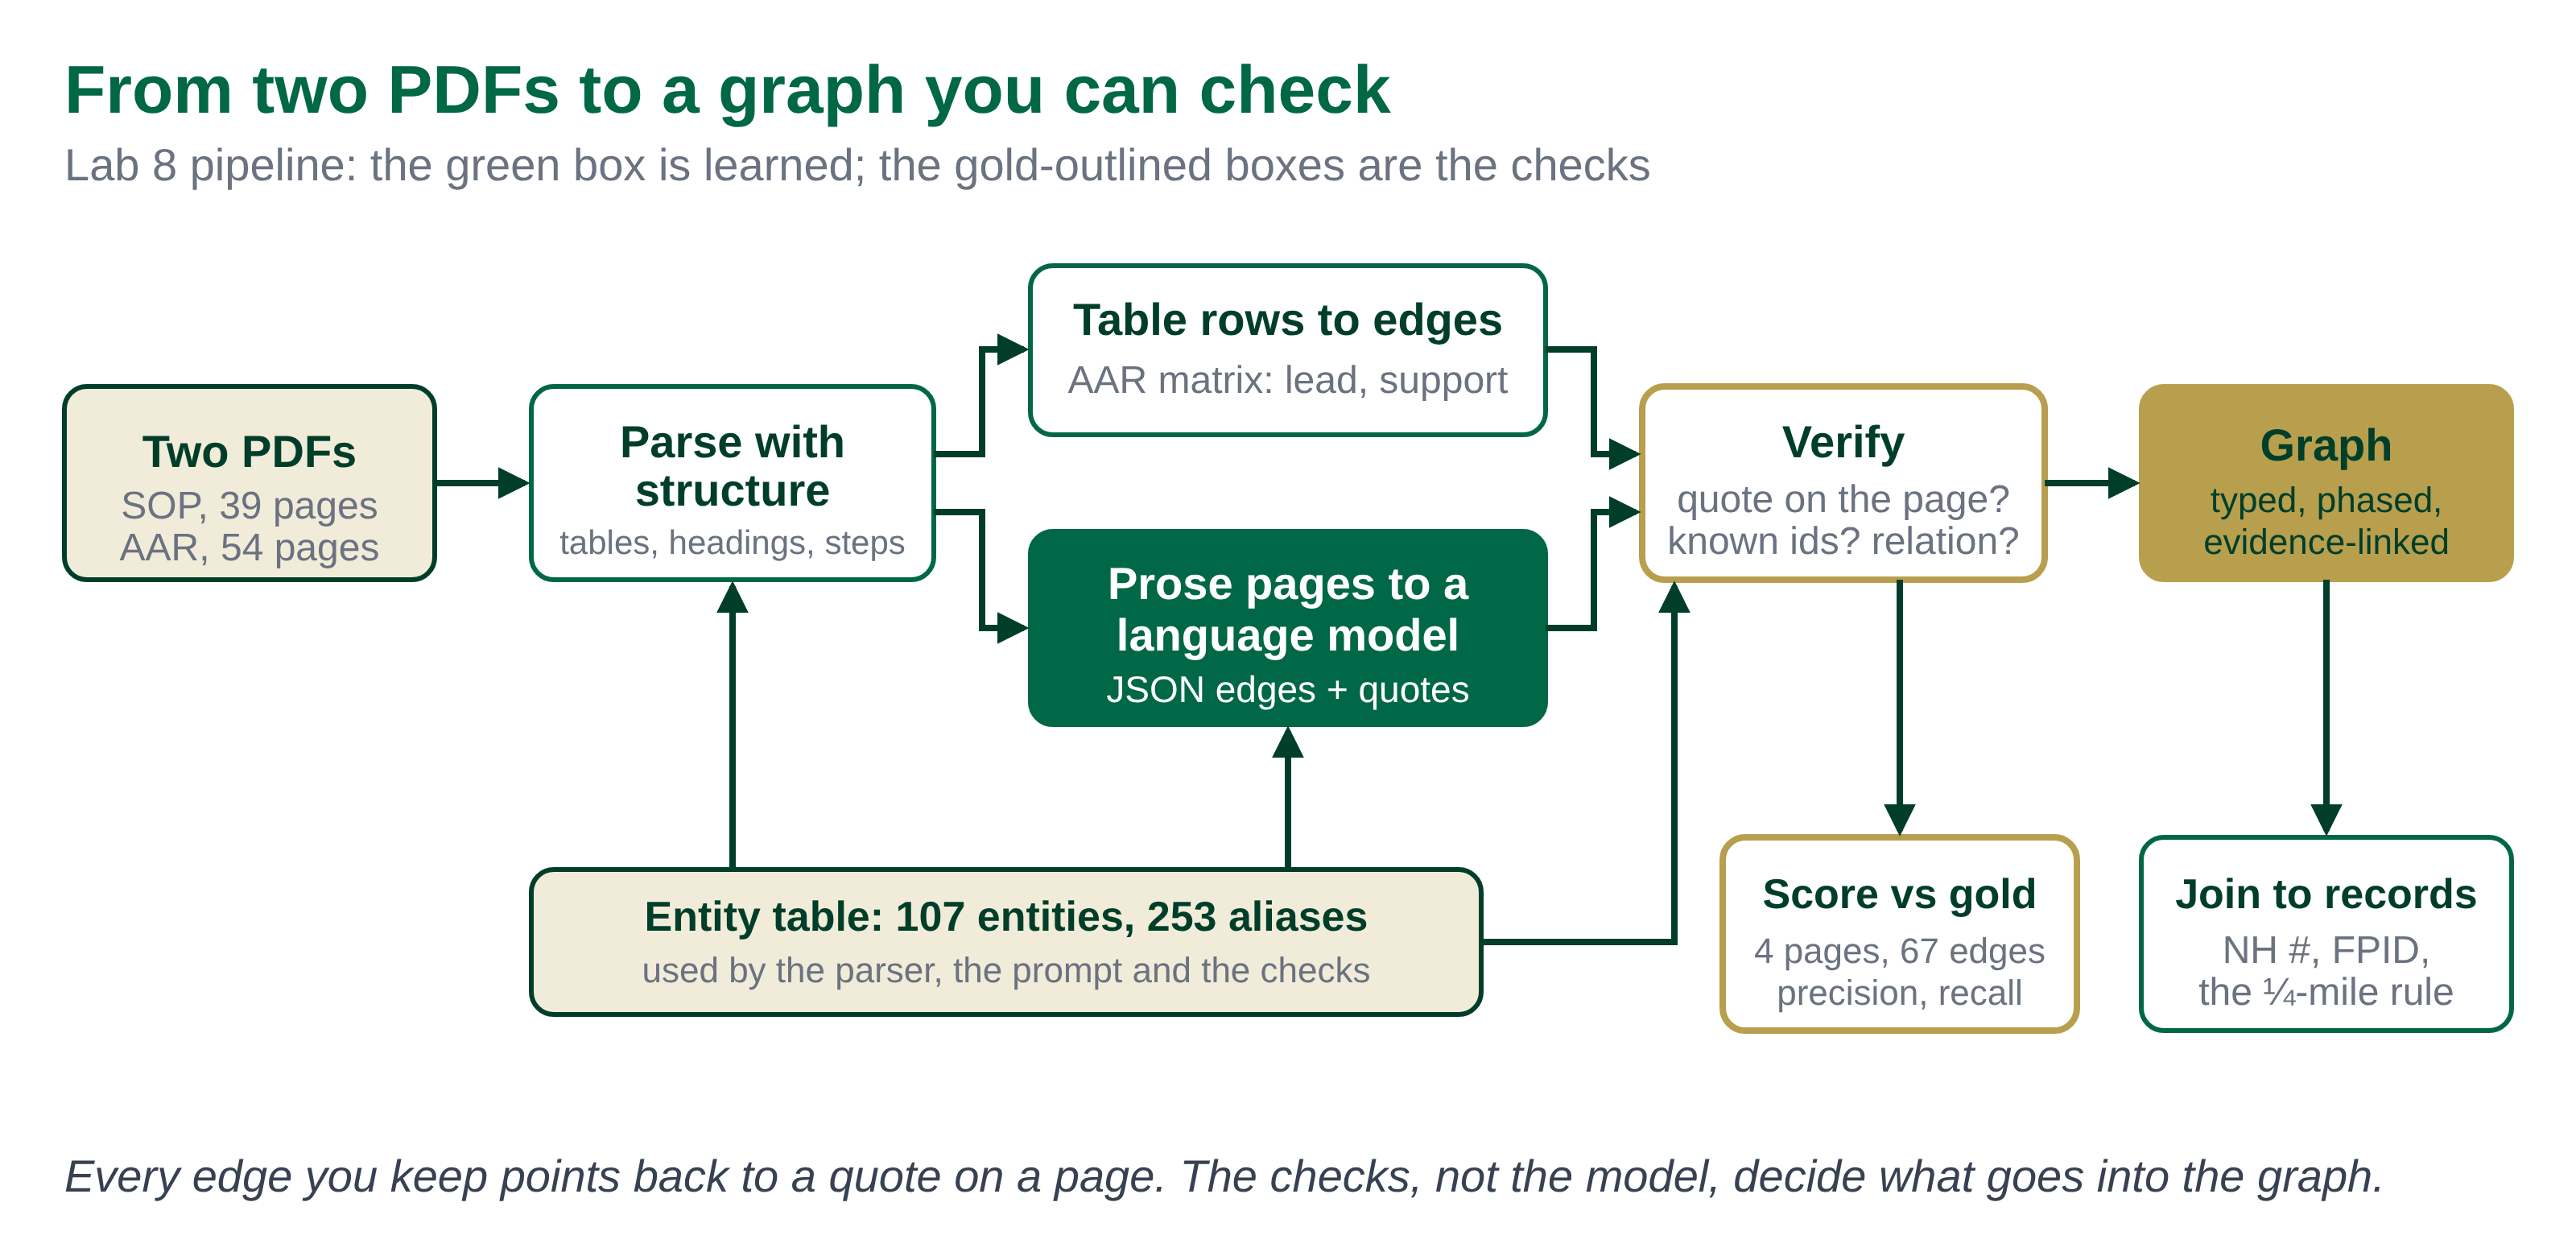

In [5]:
from IPython.display import Image, display
display(Image(filename=str(FILES / "lab8_pipeline.png"), width=900))

*From two PDFs to a graph you can check. The language model is one box in the middle; the checks around it decide
what goes into the graph.*

A schema is the list of node types, edge types and edge attributes you allow. Writing it first matters for two
reasons: two people (or a person and a model) can only agree on edges if they use the same relation words, and a
fixed list lets the computer reject anything outside it.

This lab uses **12 relations in the four classes of infrastructure interdependency** from Rinaldi, Peerenboom and
Kelly (2001): physical, cyber, geographic and logical. Each edge also gets a **modality**, because a
recommendation is not a link that exists yet. The full rules, which were given word for word to the annotator who
labeled the gold set and to the language model, are in `lab8_files/schema.md`.

In [6]:
RELATIONS = {"powers": "physical", "services": "physical", "substitutes_for": "physical",
             "informs": "cyber",
             "threatens": "geographic", "within": "geographic",
             "responsible_for": "logical", "supports": "logical", "approves": "logical",
             "precondition_of": "logical", "coordinates_with": "logical", "part_of": "logical"}
MODALITIES = {"required", "recommended", "observed", "failed"}
SCHEMA_TEXT = (FILES / "schema.md").read_text(encoding="utf-8")

ENTITIES = list(csv.DictReader(open(FILES / "entities.csv", encoding="utf-8")))
for e in ENTITIES:
    e["aliases"] = [a for a in e["aliases"].split("|") if a]
EID = {e["id"]: e for e in ENTITIES}

print(f"{len(ENTITIES)} entities, {sum(len(e['aliases']) for e in ENTITIES)} aliases")
print(pd.Series([e["type"] for e in ENTITIES]).value_counts().to_string())
print()
print(pd.DataFrame([{"relation": r, "class": c} for r, c in RELATIONS.items()]).to_string(index=False))

107 entities, 253 aliases
organization    43
team            17
asset           16
document        13
system           9
place            2
event            2
process          2
hazard           2
role             1

        relation      class
          powers   physical
        services   physical
 substitutes_for   physical
         informs      cyber
       threatens geographic
          within geographic
 responsible_for    logical
        supports    logical
        approves    logical
 precondition_of    logical
coordinates_with    logical
         part_of    logical


The entity table holds **types and roles, not individual assets**: "Portable generator", "Traffic signal",
"DDIR team". Neither document names generator NH-0412 or the signal at a particular intersection. The graph you
build from documents is therefore a **type-level graph**: it says *generators power signals* and *repairs within
¼ mile go into one DDIR*. Section 10 shows how those rules turn records into instance-level edges.

## 3 · The easy part: a table already is an edge list

The AAR's Appendix A lists every recommendation with a lead organization and supporting organizations.
`pdfplumber` can read the table cells directly. Plain text extraction would scramble the columns.

In [7]:
MATRIX = []
with pdfplumber.open(AAR_PDF) as pdf:
    for page_no in range(47, len(pdf.pages) + 1):
        for table in pdf.pages[page_no - 1].extract_tables():
            for row in table:
                cells = [(c or "").replace("\n", " ").strip() for c in row]
                if len(cells) == 7 and re.fullmatch(r"\d+\.?", cells[0]):
                    MATRIX.append(dict(num=int(cells[0].rstrip(".")), capability=cells[1], topic=cells[2],
                                       recommendation=cells[3], lead=cells[4], support=cells[5],
                                       goal=cells[6], page=page_no))
matrix = pd.DataFrame(MATRIX)
assert list(matrix.num) == list(range(1, len(matrix) + 1)), "a row is missing or out of order"
print(len(matrix), "recommendations")
matrix[["num", "topic", "lead", "support", "goal"]].tail(6)

62 recommendations


,num,topic,lead,support,goal
56,57,Resource Management,Emergency Management,"Planning Section, Logistics Section",July 2025
57,58,EOC Section Coordination,Emergency Management,"Logistics Section, Finance/Admin Section",August 2025
58,59,County Staging Area,Parks and Recreation/Emergency Management,General Services,June 2026
59,60,Warehouse Management,General Services,Emergency Services,June 2025
60,61,Property Management,Emergency Management,PDS,October 2025
61,62,Property Management,Emergency Management,"General Services, PDS",August 2025


### Split the organization cells, carefully

A cell such as `Emergency Management/Public Works/Sheriff's Office` names three organizations. The obvious move
is to split on commas and slashes. Run it and look at what comes out.

In [8]:
naive = collections.Counter()
for cell in list(matrix.lead) + list(matrix.support):
    for piece in re.split(r",|/|;", cell):
        if piece.strip():
            naive[piece.strip()] += 1
print(len(naive), "distinct names after a naive split. Some of them:")
for name in ["N", "A", "Parks", "Recreation", "and Natural Resources", "Finance", "Admin Section"]:
    print(f"  {name!r:28} appears {naive[name]} times")

51 distinct names after a naive split. Some of them:
  'N'                          appears 4 times
  'A'                          appears 4 times
  'Parks'                      appears 2 times
  'Recreation'                 appears 2 times
  'and Natural Resources'      appears 2 times
  'Finance'                    appears 1 times
  'Admin Section'              appears 1 times


"N/A" became two organizations called N and A, and "Parks, Recreation, and Natural Resources" became three. The
authors were careful: when a name contains commas they separated the cells with semicolons. A parser has to be
equally careful. Split on semicolons when a cell has them, protect the multi-part names, and drop N/A.

In [9]:
PROTECTED = ["Parks, Recreation, and Natural Resources", "Finance/Admin Section"]

def split_orgs(cell):
    cell = cell.strip()
    if cell in ("", "N/A"):
        return []
    parts = cell.split(";") if ";" in cell else [cell]
    out = []
    for part in parts:
        for i, name in enumerate(PROTECTED):
            part = part.replace(name, f"@{i}@")
        for piece in re.split(r",|/", part):
            piece = piece.strip()
            m = re.fullmatch(r"@(\d+)@", piece)
            out.append(PROTECTED[int(m.group(1))] if m else piece)
    return [p for p in out if p]

careful = collections.Counter(n for cell in list(matrix.lead) + list(matrix.support) for n in split_orgs(cell))
print(len(careful), "distinct names after a careful split")
print(split_orgs("Solid Waste; Public Works; Parks, Recreation, and Natural Resources; PDS"))
print(split_orgs("Logistics Section, Finance/Admin Section"), split_orgs("N/A"))

46 distinct names after a careful split
['Solid Waste', 'Public Works', 'Parks, Recreation, and Natural Resources', 'PDS']
['Logistics Section', 'Finance/Admin Section'] []


## 4 · Entity resolution: one thing, one node

Even after a careful split, one organization can appear under several names: `OFM` and `Office of Financial
Management`, `PDS` and `Planning and Development Services`, `Fire`, `Sarasota Fire` and `Sarasota County Fire`.
Each needs to become one node, or the graph will show three fire departments with one edge each.

The entity table carries every alias that was approved for a merge. Resolving a name is a lookup.

In [10]:
ALIAS = {}
for e in ENTITIES:
    for a in e["aliases"] + [e["name"]]:
        ALIAS[norm(a)] = e["id"]

def resolve(name):
    key = norm(name)
    return ALIAS.get(key) or ALIAS.get(re.sub(r"^the ", "", key))

raw_names = sorted(careful)
resolved = {n: resolve(n) for n in raw_names}
missing = [n for n, r in resolved.items() if r is None]
assert not missing, f"names with no entity: {missing}"

merged = collections.defaultdict(list)
for n, r in resolved.items():
    merged[r].append(n)
print(f"{len(raw_names)} raw names -> {len(merged)} organizations")
pd.DataFrame([{"entity": EID[r]["name"], "raw names in the matrix": " | ".join(ns)}
              for r, ns in merged.items() if len(ns) > 1])

46 raw names -> 39 organizations


,entity,raw names in the matrix
0,Sarasota County Fire Department,Fire | Sarasota County Fire | Sarasota Fire
1,Human Resources,HR (Risk) | Human Resources
2,Law enforcement agencies,Law Enforcement | law enforcement partners
3,Office of Financial Management,OFM | Office of Financial Management
4,Planning and Development Services,PDS | Planning and Development Services
5,"Parks, Recreation, and Natural Resources","Parks and Recreation | Parks, Recreation, and Natural Resources"


**Who approves a merge?** Merging `Fire` into the County Fire Department is a judgment, not a string match: in
another document "Fire" could mean a city department. Keep merges in a table that a person signs off, as here, and
never let a fuzzy-match score merge two organizations on its own.

The SOP even ships its own dictionary: the list of acronyms on page 4. Read it, and check which acronyms the
entity table already covers.

In [11]:
ACRONYMS = {}
for line in PAGES[("SOP", 4)].splitlines():
    m = re.match(r"^([A-Z]{2,6})\s*\.{3,}\s*(.+)$", line.strip())
    if m:
        ACRONYMS[m.group(1)] = m.group(2).strip()
covered = {a: resolve(a) or resolve(full) for a, full in ACRONYMS.items()}
print(f"{len(ACRONYMS)} acronyms on SOP page 4")
print(pd.DataFrame([{"acronym": a, "meaning": ACRONYMS[a], "entity": covered[a] or "-- not in the table --"}
                    for a in ACRONYMS]).to_string(index=False))

16 acronyms on SOP page 4
acronym                                   meaning                 entity
   ATMS        Advanced Traffic Management System                   atms
   CCTV                 Closed Circuit Television                   cctv
    CEI Construction, Engineering, and Inspection                    cei
     CO                            Central Office                fdot_co
   DDIR         Detailed Damage Inspection Report                   ddir
    EOC               Emergency Operations Center                    eoc
    ERS                Emergency Response Service -- not in the table --
   FDOT      Florida Department of Transportation                fdot_d7
   FPID          Financial Project Identification                   fpid
    GIS             Geographic Information System                    gis
    GPS                 Global Positioning System -- not in the table --
   RTMC Regional Transportation Management Center                   rtmc
    SAT                Si

Two lessons in that table. Three acronyms (ERS, GPS, SLD) are not in the entity table, because no edge on the
extracted pages needed them; add them before you extend the lab to pages that use them. And one acronym resolves to
**the wrong thing**: the SOP's GIS is a technology (Geographic Information System), while the entity it matched is
the County's GIS division from the AAR matrix. Same string, different node. A lookup cannot catch that; a person
reading the merge table can.

Now the matrix becomes edges. Each recommendation is a node. The lead organization is `responsible_for` it, and
each supporter `supports` it.

In [12]:
MATRIX_EDGES = []
for r in MATRIX:
    rec = f"rec_{r['num']:02d}"
    for role, rel in [("lead", "responsible_for"), ("support", "supports")]:
        for name in split_orgs(r[role]):
            MATRIX_EDGES.append(dict(doc="AAR", page=r["page"], subject=resolve(name), relation=rel, object=rec,
                                     modality="recommended", evidence=r["recommendation"], source="matrix"))
medges = pd.DataFrame(MATRIX_EDGES)
lead_counts = medges[medges.relation == "responsible_for"].subject.value_counts()
print(f"{len(medges)} edges: {sum(medges.relation == 'responsible_for')} lead, {sum(medges.relation == 'supports')} support, "
      f"among {medges.subject.nunique()} organizations and {len(MATRIX)} recommendations")
print(f"Emergency Management leads {lead_counts['sc_em']} of the {len(MATRIX)} recommendations "
      f"({lead_counts['sc_em'] / len(MATRIX):.0%}).")
print(lead_counts.head(6).rename(index=lambda i: EID[i]["name"]).to_string())

167 edges: 76 lead, 91 support, among 39 organizations and 62 recommendations
Emergency Management leads 49 of the 62 recommendations (79%).
subject
Sarasota County Emergency Management    49
Human Resources                          5
Office of Financial Management           3
Solid Waste                              3
Planning and Development Services        2
Public Works                             2


**Read that last number as a graph result.** One node is the lead on most of the improvement plan. That matches
the AAR's own description of Emergency Management as "the lead coordinating entity", and it is also what a
single point of failure looks like in a graph: if that office is short-staffed during the next activation, most
of the plan stalls at once. You found it by counting edges, without a model.

## 5 · The hard part starts: prose, but prose with structure

Most of the interesting links are in sentences. Before any model reads them, use the structure the authors gave
you. In the SOP, every step sits under a phase heading and has a number, so each step, and every edge found in
it, gets a **time window** for free.

In [13]:
PHASES = ["One Month Prior to Hurricane Season", "One Week Prior to Storm", "Three Days Prior to Storm",
          "48 Hours Prior to Storm", "24 Hours Prior to Storm", "Three Hours Prior to Storm",
          "Immediately Post Storm", "Ongoing Efforts", "0-1 Week Post Storm",
          "Emergency Task Works Orders (TWO)", "0-1 Month Post Storm", "0-4 Months Post Storm"]
SKIP = re.compile(r"^(Pre-Storm Procedures|Post-Storm Procedures|Traffic Signals Standard Operating Procedures.*)$")

STEPS, phase = [], None
for p in range(5, 12):
    for line in PAGES[("SOP", p)].splitlines():
        line = line.strip()
        if not line or SKIP.match(line):
            continue
        if line in PHASES:
            phase = line
            continue
        m = re.match(r"^(\d+(?:\.\d+)*)\.\s+(.*)$", line)
        if m:
            STEPS.append(dict(page=p, phase=phase, step=m.group(1), depth=m.group(1).count(".") + 1,
                              text=m.group(2)))
        elif STEPS:
            STEPS[-1]["text"] += " " + line     # a sentence that runs onto the next line
steps = pd.DataFrame(STEPS)
steps["phase_order"] = steps.phase.map({ph: i for i, ph in enumerate(PHASES)})
print(len(steps), "steps on SOP pages 5-11")
print(steps.groupby(["phase_order", "phase"]).size().rename("steps").to_string())

150 steps on SOP pages 5-11
phase_order  phase                              
0            One Month Prior to Hurricane Season    29
1            One Week Prior to Storm                20
2            Three Days Prior to Storm               5
3            48 Hours Prior to Storm                 4
4            24 Hours Prior to Storm                 3
5            Three Hours Prior to Storm              5
6            Immediately Post Storm                 29
7            Ongoing Efforts                         8
8            0-1 Week Post Storm                    14
9            Emergency Task Works Orders (TWO)      14
10           0-1 Month Post Storm                   12
11           0-4 Months Post Storm                   7


In [14]:
def locate_step(page, quote):
    """The SOP step on this page that contains the quote (or its first six words)."""
    q = norm(quote)
    cand = steps[steps.page == page]
    for probe in [q, " ".join(q.split()[:6])]:
        hit = cand[cand.text.map(lambda t: probe in norm(t))]
        if len(hit):
            return hit.iloc[0]
    return None

s = locate_step(10, "Once DDIRs are approved")
print(s.phase, "| step", s.step, "|", s.text[:90])

0-1 Month Post Storm | step 3 | Once DDIRs are approved, take list to Work Program for team to issue FPIDs for emergency a


The AAR has no numbering, and its layout fights you. Photo captions sit inside the text columns, so text
extraction drops them into the middle of sentences. Here is the sentence about the Regional Law Enforcement
Coordination Team as `pdfplumber` reads it:

In [15]:
t = NPAGES[("AAR", 30)]
i = t.find("rlect provides")
print("..." + t[i - 20:i + 140] + "...")

...n ft myers, fl. the rlect provides support for law enforcement teams county eoc briefing, hurricane debby deploying to assist impacted jurisdictions. some eoc s...


The words "county eoc briefing, hurricane debby" are a photo caption. A quote that spans the caption will not be
found on the page, so a model that "fixes" the sentence will fail the evidence check in section 7. That is the
right outcome: the check rewards copying what is there.

## 6 · Getting edges out of the prose

### 6a · Baseline: join everything named together

The cheapest extractor finds every entity name in a step (SOP) or a sentence (AAR) and joins every pair. It cannot
tell a power link from an approval, and it cannot see the implied actor, so it produces untyped edges only. If a
language model does not beat this, it has not earned its cost.

In [16]:
def alias_pattern(a):
    a = light(a)
    if a.isupper() or len(a) <= 3:               # short acronyms must match exactly, case included
        return re.compile(r"(?<![A-Za-z0-9])" + re.escape(a) + r"(?![A-Za-z0-9])")
    stem = a[:-1] if (a.endswith("s") and len(a) > 4) else a   # rule 1: a plural is fine
    return re.compile(r"(?<![A-Za-z0-9])" + re.escape(stem) + r"(?:s|es)?(?![A-Za-z0-9])", re.IGNORECASE)

PATTERNS = [(alias_pattern(a), e["id"], len(a)) for e in ENTITIES for a in e["aliases"]]

def mentions(text):
    """Entity ids named in text (singular or plural); the longest alias wins where two overlap ('eSTORM Lite' over 'eSTORM')."""
    text = light(text)
    spans = sorted(((m.start(), m.end(), eid) for pat, eid, _ in PATTERNS for m in pat.finditer(text)),
                   key=lambda s: (-(s[1] - s[0]), s[0]))
    taken, found = [], set()
    for a, b, eid in spans:
        if all(b <= x or a >= y for x, y in taken):
            taken.append((a, b))
            found.add(eid)
    return found

EXTRACT_PAGES = {"SOP": [5, 6, 7, 8, 9, 10, 11], "AAR": [30, 38, 39, 40]}

def units(doc, page):
    if doc == "SOP":
        return list(steps[steps.page == page].text)
    flat = re.sub(r"\s+", " ", PAGES[(doc, page)])
    return re.split(r"(?<=[.!?])\s+", flat)

BASE = set()
for doc, plist in EXTRACT_PAGES.items():
    for p in plist:
        for u in units(doc, p):
            for a, b in itertools.combinations(sorted(mentions(u)), 2):
                BASE.add((doc, p, frozenset((a, b))))
print(len(BASE), "untyped baseline edges on the 11 pages")
print(sorted(mentions("A yellow or red status in the ATMS signal system should be used to help prioritize "
                      "SAT and generator deployment teams.")))

288 untyped baseline edges on the 11 pages
['atms', 'gen_team', 'sat']


### 6b · A language model with the schema

Each of the 11 pages was sent as its own prompt: the schema and rules, the entity table, and the page text read by
the code above. The model was asked for JSON only, one object per edge, each with an exact quote.

**How the shipped runs were made.** Claude, in a fresh session that was given only the prompt files and no access
to the gold set, answered all 11 prompts. This was done twice, independently, on October 29, 2026: run A and run B.
Two runs let you see how much the answer changes when nothing in the input changes.

The cell below rebuilds the prompt for SOP page 8 from scratch and checks that it is byte for byte the prompt the
model saw.

In [17]:
DOC_TITLES = {"SOP": "FDOT District 7 Traffic Signals SOP Reference Guide (June 2025)",
              "AAR": "Sarasota County 2024 Hurricane Season After-Action Report (May 2025)"}

def build_prompt(doc, page, page_text, entities, schema_text):
    table = "\n".join(f"{e['id']} | {e['type']} | {e['name']} | {'; '.join(e['aliases'])}" for e in entities)
    return f"""You are extracting a dependency graph from an agency document for a transportation research project.
Read the page below and list every edge it states, using only the schema and the entity table.

SCHEMA AND RULES
{schema_text.strip()}

ENTITY TABLE (id | type | name | aliases)
{table}

OUTPUT
Return JSON only, in this shape:
{{"edges": [{{"subject": "<entity id>", "relation": "<relation>", "object": "<entity id>", "modality": "<modality>", "evidence": "<exact quote from the page>"}}],
 "new_entities": [{{"name": "<as written on the page>", "type": "<type>", "evidence": "<exact quote>"}}]}}
Use new_entities for things the page names that are not in the table and that you would have needed for an edge. Do not invent ids.

PAGE ({DOC_TITLES[doc]}, PDF page {page})
{page_text.strip()}
"""

prompt = build_prompt("SOP", 8, PAGES[("SOP", 8)], ENTITIES, SCHEMA_TEXT)
assert prompt == (FILES / "prompts" / "SOP_08.txt").read_text(encoding="utf-8"), "prompt differs from the shipped one"
print(f"The prompt for SOP page 8 is {len(prompt.split()):,} words. Its last lines:\n")
print("\n".join(prompt.splitlines()[-12:]))

The prompt for SOP page 8 is 2,388 words. Its last lines:

5. Operational Checks utilizing ATMS signal system. Confirm signals are operating correctly upon power
restoration. Report any signals in flash or not functioning properly.
6. Situational Awareness Team (SAT)
6.1. Deploy SAT to intersections and follow assigned corridors. SAT assessments will continue twice
daily at 9:00 AM and 2:00 PM, as intermittent commercial power restoration is ongoing.
6.2. Maintain share repair/tracking spreadsheet for ongoing coordination.
6.3. Provide continuous updates on repair progress and issues encountered. eSTORM updates shall be
made as soon as possible.
6.4. Detailed assessments, including pictures of damage with GPS locations.
7. Deploy DAT personnel. Consider requesting them to report signals, speed feedback signs, and beacons
that are not found in eSTORM.
Traffic Signals Standard Operating Procedures (SOP) Reference Guide 4


**Make your own run with your Claude account (no API key needed).** Uncomment the first line of the cell below to
print a prompt, paste it into a new Claude chat, and paste the JSON it returns into `MY_ANSWER`. Section 7 checks
your answer exactly as it checks runs A and B. If you do have API access, the commented lines at the bottom show
the equivalent call.

In [18]:
# print(build_prompt("SOP", 7, PAGES[("SOP", 7)], ENTITIES, SCHEMA_TEXT))   # copy this into Claude
MY_ANSWER = """"""          # paste the JSON here, then set MY_PAGE to the page you sent
MY_PAGE = ("SOP", 7)

# With an API key instead (optional):
# import anthropic; client = anthropic.Anthropic()
# msg = client.messages.create(model="claude-opus-5-5", max_tokens=8000,
#                              messages=[{"role": "user", "content": build_prompt("SOP", 7, PAGES[("SOP", 7)], ENTITIES, SCHEMA_TEXT)}])
# MY_ANSWER = msg.content[0].text

In [19]:
def parse_answer(text):
    text = text.strip()
    text = re.sub(r"^```(?:json)?|```$", "", text).strip()
    return json.loads(text)

def load_run(name):
    rows, new = [], []
    for f in sorted((FILES / name).glob("*.json")):
        doc, page = f.stem.split("_")
        ans = parse_answer(f.read_text(encoding="utf-8"))
        for e in ans.get("edges", []):
            rows.append(dict(doc=doc, page=int(page), **{k: e.get(k, "") for k in
                         ["subject", "relation", "object", "modality", "evidence"]}, source=name))
        for e in ans.get("new_entities", []):
            new.append(dict(doc=doc, page=int(page), **e))
    return pd.DataFrame(rows), pd.DataFrame(new)

runA, newA = load_run("llm_run_A")
runB, newB = load_run("llm_run_B")
RUNS = {"run A": runA, "run B": runB}
if MY_ANSWER.strip():
    ans = parse_answer(MY_ANSWER)
    RUNS["my run"] = pd.DataFrame([dict(doc=MY_PAGE[0], page=MY_PAGE[1], source="my run",
                                        **{k: e.get(k, "") for k in ["subject", "relation", "object", "modality", "evidence"]})
                                   for e in ans.get("edges", [])])
pd.DataFrame({name: df.groupby(["doc", "page"]).size() for name, df in RUNS.items()}).fillna(0).astype(int).T

doc   AAR            SOP                       
page   30  38  39 40  5   6   7   8   9   10 11
run A  13  15  18  7  17  13  18  17  14  23  8
run B  13  12  17  7  15  11  19  13  15  23  9

## 7 · Verify every edge before you keep it

A model's edge is a claim. Four checks, all automatic, decide whether the claim is even eligible:

1. **Known relation and modality.** Anything outside the schema is rejected.
2. **Known entities.** An id that is not in the table is rejected (a proposed new entity goes to a person instead).
3. **The quote is on the cited page**, after `norm()`. This is the check that catches an edge the page does not
   support.
4. **Both ends are named on the page** (rule 1), counting District 7 as named on every SOP page (rule 2). An end
   that the page never mentions came from somewhere else: another page, or the model's general knowledge.

In [20]:
PAGE_MENTIONS = {(d, p): mentions(PAGES[(d, p)]) for d, plist in EXTRACT_PAGES.items() for p in plist}

def verify(row):
    if row.relation not in RELATIONS: return "unknown relation"
    if row.modality not in MODALITIES: return "unknown modality"
    if row.subject not in EID or row.object not in EID: return "unknown entity id"
    if row.subject == row.object: return "an edge from a node to itself"
    q = norm(str(row.evidence))
    if not q or q not in NPAGES[(row.doc, row.page)]: return "quote not on the page"
    if len(q.split()) > 30: return "quote longer than 30 words"
    named = PAGE_MENTIONS[(row.doc, row.page)] | ({"fdot_d7"} if row.doc == "SOP" else set())  # rule 2
    if row.subject not in named or row.object not in named: return "an end is not named on the page"
    return "ok"

for name, df in RUNS.items():
    df["check"] = df.apply(verify, axis=1)
gold_check = pd.read_csv(FILES / "gold_edges.csv").apply(verify, axis=1).value_counts()
print("The gold set, put through the same checks:", dict(gold_check), "\n")
summary = pd.DataFrame({name: df.check.value_counts() for name, df in RUNS.items()}).fillna(0).astype(int)
summary

The gold set, put through the same checks: {'ok': np.int64(67)} 



,run A,run B
check,,
ok,161,152
an end is not named on the page,2,2


In [21]:
bad = pd.concat([df[df.check != "ok"] for df in RUNS.values()])
bad[["source", "doc", "page", "subject", "relation", "object", "check", "evidence"]].head(12)

,source,doc,page,subject,relation,object,check,evidence
71,llm_run_A,SOP,6,contractors,responsible_for,damage_report,an end is not named on the page,Remind Contractors/CEI to take photos of the damage and repairs
72,llm_run_A,SOP,6,cei,responsible_for,damage_report,an end is not named on the page,Remind Contractors/CEI to take photos of the damage and repairs
64,llm_run_B,SOP,6,contractors,responsible_for,damage_report,an end is not named on the page,Remind Contractors/CEI to take photos of the damage and repairs with context
65,llm_run_B,SOP,6,cei,responsible_for,damage_report,an end is not named on the page,Remind Contractors/CEI to take photos of the damage and repairs with context


**What the checks caught, and what they did not.** All 67 gold edges pass, so the checks are not stricter than a
careful reader. Each run lost the same two edges: contractors and CEI made `responsible_for` the damage report, from
"take photos of the damage and repairs". The page never names that entity; the model inferred it. That is exactly
the kind of edge a person should decide on, and the check sends it to one.

No quote failed to match its page. With a rule that says "copy it exactly", both runs copied. Keep in mind what the
checks cannot see: an edge with a real quote, real entities and the wrong relation passes all four. Section 8 is
where those show up.

In [22]:
KEPT = {name: df[df.check == "ok"].drop_duplicates(["doc", "page", "subject", "relation", "object"]).copy()
        for name, df in RUNS.items()}
for name, df in KEPT.items():
    df["class"] = df.relation.map(RELATIONS)
    df["phase"] = [ (locate_step(r.page, r.evidence).phase if r.doc == "SOP" and locate_step(r.page, r.evidence) is not None else "")
                    for r in df.itertuples()]
    print(f"{name}: {len(df)} verified edges kept out of {len(RUNS[name])}")

run A: 161 verified edges kept out of 163
run B: 152 verified edges kept out of 154


## 8 · Score against the gold set

The gold set holds every edge on four pages, labeled with the same rules: SOP page 8 (immediately post storm), SOP
page 10 (task work orders and the first month), AAR page 30 (bridges and law enforcement) and AAR page 39
(stormwater and lift stations). One annotator labeled it, page by page against `schema.md`, and it was frozen
before either model run. Its fingerprint is printed below so you can tell if anyone has edited it since.

Two scores. **Typed**: subject, relation and object must all match. **Untyped**: the two ends must match in either
order, whatever the relation. The baseline can only be scored untyped.

In [23]:
gold = pd.read_csv(FILES / "gold_edges.csv")
print("gold set:", len(gold), "edges; sha256", hashlib.sha256((FILES / "gold_edges.csv").read_bytes()).hexdigest()[:16])
GOLD_PAGES = set(zip(gold.doc, gold.page))
G_TYPED = set(zip(gold.doc, gold.page, gold.subject, gold.relation, gold.object))
G_UNTYPED = {(d, p, frozenset((s, o))) for d, p, s, r, o in G_TYPED}

def prf(pred, truth):
    tp = len(pred & truth)
    p = tp / len(pred) if pred else 0.0
    r = tp / len(truth) if truth else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

def typed(df):
    return {(d, p, s, r, o) for d, p, s, r, o in zip(df.doc, df.page, df.subject, df.relation, df.object)
            if (d, p) in GOLD_PAGES}

def untyped(df):
    return {(d, p, frozenset((s, o))) for d, p, s, r, o in typed(df)}

rows = [dict(method="co-occurrence baseline", edges=len({e for e in BASE if e[:2] in GOLD_PAGES}),
             **dict(zip(["untyped P", "untyped R", "untyped F1"],
                        prf({e for e in BASE if e[:2] in GOLD_PAGES}, G_UNTYPED))))]
for name in RUNS:
    for label, df in [(f"{name}, everything it returned", RUNS[name]), (f"{name}, verified edges only", KEPT[name])]:
        if not len(typed(df)):
            continue
        rows.append(dict(method=label, edges=len(typed(df)),
                         **dict(zip(["typed P", "typed R", "typed F1"], prf(typed(df), G_TYPED))),
                         **dict(zip(["untyped P", "untyped R", "untyped F1"], prf(untyped(df), G_UNTYPED)))))
scores = pd.DataFrame(rows).set_index("method")
scores.round(2)

gold set: 67 edges; sha256 4c646eecb71de26b


,edges,untyped P,untyped R,untyped F1,typed P,typed R,typed F1
method,,,,,,,
co-occurrence baseline,115,0.45,0.81,0.58,NaN,NaN,NaN
"run A, everything it returned",71,0.88,0.92,0.90,0.79,0.84,0.81
"run A, verified edges only",71,0.88,0.92,0.90,0.79,0.84,0.81
"run B, everything it returned",66,0.86,0.86,0.86,0.80,0.79,0.80
"run B, verified edges only",66,0.86,0.86,0.86,0.80,0.79,0.80


In [24]:
A, B = set(map(tuple, KEPT["run A"][["doc", "page", "subject", "relation", "object"]].values)), \
       set(map(tuple, KEPT["run B"][["doc", "page", "subject", "relation", "object"]].values))
print(f"Run A and run B agree on {len(A & B)} verified edges; {len(A - B)} only in A, {len(B - A)} only in B "
      f"(Jaccard {len(A & B) / len(A | B):.2f}) across all 11 pages.")
both = A & B
print("Edges found by both runs, scored on the gold pages: P = {:.2f}, R = {:.2f}, F1 = {:.2f}".format(
      *prf({e for e in both if e[:2] in GOLD_PAGES}, G_TYPED)))

Run A and run B agree on 138 verified edges; 23 only in A, 14 only in B (Jaccard 0.79) across all 11 pages.
Edges found by both runs, scored on the gold pages: P = 0.85, R = 0.76, F1 = 0.80


### Look at the mistakes, not just the score

In [25]:
kA = KEPT["run A"]
pred = typed(kA)
gold_idx = gold.set_index(["doc", "page", "subject", "relation", "object"])
miss = sorted(G_TYPED - pred)
extra = sorted(pred - G_TYPED)
print(f"Run A misses {len(miss)} gold edges and adds {len(extra)} that the gold set does not have.\n")
print("Missed (in the gold set, not in run A):")
for k in miss[:10]:
    print(f"  {k[0]} p{k[1]}: {k[2]} -{k[3]}-> {k[4]}   | {gold_idx.loc[k].evidence[:70]}")
print("\nExtra (in run A, not in the gold set):")
ev = kA.set_index(["doc", "page", "subject", "relation", "object"]).evidence
for k in extra[:10]:
    print(f"  {k[0]} p{k[1]}: {k[2]} -{k[3]}-> {k[4]}   | {str(ev.loc[k])[:70]}")

Run A misses 11 gold edges and adds 15 that the gold set does not have.

Missed (in the gold set, not in run A):
  AAR p30: city_sarasota -responsible_for-> closure   | Each jurisdiction needs to be involved in the efforts to close and/or 
  AAR p30: eoc_staff -coordinates_with-> rlect   | Some EOC staff were unfamiliar with the full spectrum of RLECT support
  AAR p30: sc_fire -coordinates_with-> eoc   | Having these additional fire personnel at the EOC was helpful to coord
  AAR p30: state_fl -responsible_for-> closure   | Each jurisdiction needs to be involved in the efforts to close and/or 
  AAR p39: fpl -powers-> booster_pump   | FPL maintains a power meter inventory that assigns a meter to critical
  SOP p8: local_agency -responsible_for-> generator   | Coordinate with agencies for local generator deployment
  SOP p8: sat -informs-> tracking_sheet   | Maintain share repair/tracking spreadsheet for ongoing coordination
  SOP p8: sat -responsible_for-> signal   | Deploy SAT to int

In [26]:
# Same two ends, different relation: where the schema itself is hard to apply
pairs_pred = collections.defaultdict(set)
for d, p, s, r, o in pred:
    pairs_pred[(d, p, frozenset((s, o)))].add(r)
conf = collections.Counter()
for d, p, s, r, o in G_TYPED:
    got = pairs_pred.get((d, p, frozenset((s, o))), set())
    if got and r not in got:
        for g in got:
            conf[(r, g)] += 1
pd.DataFrame([{"gold relation": a, "run A relation": b, "edges": n} for (a, b), n in conf.most_common()])

,gold relation,run A relation,edges
0,responsible_for,supports,2
1,coordinates_with,within,1
2,informs,coordinates_with,1
3,coordinates_with,informs,1
4,informs,responsible_for,1


In [27]:
# On the edges that both run A and the gold set have: does the model give the same modality?
keys = ["doc", "page", "subject", "relation", "object"]
both_keys = sorted(set(kA.set_index(keys).index) & set(gold.set_index(keys).index))
mod = pd.DataFrame({"gold": gold.set_index(keys).modality.loc[both_keys].values,
                    "run A": kA.set_index(keys).modality.loc[both_keys].values})
print(f"Same modality on {(mod.gold == mod['run A']).mean():.0%} of the {len(mod)} matched edges")
pd.crosstab(mod.gold, mod["run A"])

Same modality on 93% of the 56 matched edges


run A,observed,recommended,required
gold,,,
failed,1,0,0
observed,19,0,2
recommended,0,3,0
required,0,1,30


**Reading the scores.**

- **The baseline** finds most of the right pairs (untyped recall 0.81), because linked things are usually named
  together. But more than half of what it returns is wrong (precision 0.45): naming two things in one sentence is
  not a link.
- **Run A** nearly doubles the precision (0.88 untyped) while also raising recall (0.92), and it names the relation
  correctly for most edges (typed F1 0.81). Run B is close behind (typed F1 0.80).
- **The checks removed no wrong edge on the gold pages**: the verified scores equal the raw ones. Every extra edge
  had a real quote and known entities. The checks protect you from made-up support; only a labeled sample tells you
  whether the reading is right.
- **The two runs agree on 138 of 175 distinct verified edges** (Jaccard 0.79). Keeping only the edges both runs
  found raises typed precision to 0.85 and lowers recall to 0.76. That is a dial you choose, not a free improvement.
- **Many "errors" are disagreements about the schema, not about the page.** On AAR page 30 the gold set says each
  jurisdiction is `responsible_for` closing the North Bridge; run A says each `supports` it. Both are defensible.
  On page 39 run A made lift stations `part_of` the FPL meter inventory, which the page does say in its own words.
  A schema needs worked examples for its hard cases, and a gold set labeled by one person carries that person's
  habits (exercise 1).
- **Modality is the easiest attribute** (93% agreement on matched edges), but the one disagreement is the one that
  matters most. The gold set marks the meter-inventory edge `failed`, because the County did not know about it until
  Milton; run A called it `observed`.

| Before you trust this result | |
| --- | --- |
| **What is the baseline?** | Co-occurrence: join every pair of entities named in the same SOP step or AAR sentence. It costs nothing and needs no model. |
| **How was the data split, and why is that honest?** | The gold set covers 4 of the 11 extracted pages and was frozen before either model run. The model never saw it. Scores are reported only on those 4 pages. |
| **What does it do on the ugly cases?** | Look at the misses and extras above: implied actors, a relation that two careful readers would name differently, and captions inside sentences. The gold set had one annotator, so part of the disagreement is the gold set's. Exercise 1 asks you to measure that. |

## 9 · Build the graph and ask it questions

The graph combines the verified edges from run A on all 11 pages with the matrix edges from section 4. Every edge
keeps its relation, class, modality, page, quote and, for the SOP, its phase.

In [28]:
G = nx.MultiDiGraph()
for e in ENTITIES:
    G.add_node(e["id"], name=e["name"], type=e["type"])
for r in MATRIX:
    G.add_node(f"rec_{r['num']:02d}", name=f"Rec. {r['num']}: {r['topic']}", type="recommendation")
for df in [KEPT["run A"], medges.assign(**{"class": "logical", "phase": ""})]:
    for r in df.itertuples():
        G.add_edge(r.subject, r.object, key=r.relation, relation=r.relation, cls=RELATIONS[r.relation],
                   modality=r.modality, doc=r.doc, page=r.page, evidence=r.evidence, phase=r.phase)
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")
print(pd.Series([d["cls"] for _, _, d in G.edges(data=True)]).value_counts().to_string())

166 nodes, 303 edges
logical       231
cyber          44
physical       17
geographic     11


**Question 1. What has to be in place before District 7 can issue an emergency task work order?** Follow the
`precondition_of` and `approves` edges backward.

In [29]:
def name(n): return G.nodes[n].get("name", n)

H = nx.DiGraph([(u, v, {"relation": d["relation"]}) for u, v, d in G.edges(data=True)
                if d["relation"] in ("precondition_of", "approves")])
target = "two_emergency"
for n in nx.ancestors(H, target) if target in H else []:
    for path in nx.all_simple_paths(H, n, target):
        print("  " + "  ->  ".join(f"{name(a)} [{H[a][b]['relation']}]" for a, b in zip(path, path[1:])) + f"  ->  {name(target)}")

  Funding request and approval [precondition_of]  ->  Emergency Task Work Order (TWO)
  FDOT District 7 [approves]  ->  Funding request and approval [precondition_of]  ->  Emergency Task Work Order (TWO)
  D7 District Maintenance Engineer [approves]  ->  Funding request and approval [precondition_of]  ->  Emergency Task Work Order (TWO)
  State of Emergency [precondition_of]  ->  Emergency Task Work Order (TWO)
  Governor's executive order [precondition_of]  ->  Emergency Task Work Order (TWO)
  FDOT Central Office [approves]  ->  Funding request and approval [precondition_of]  ->  Emergency Task Work Order (TWO)


**Question 2. What does a traffic signal depend on after a storm?** Everything with an edge into `signal`, and one
step further back.

In [30]:
rows = []
for u, v, d in G.in_edges("signal", data=True):
    rows.append(dict(hop=1, source=name(u), relation=d["relation"], target=name(v), page=f"{d['doc']} p{d['page']}",
                     phase=d["phase"]))
    for u2, v2, d2 in G.in_edges(u, data=True):
        rows.append(dict(hop=2, source=name(u2), relation=d2["relation"], target=name(v2),
                         page=f"{d2['doc']} p{d2['page']}", phase=d2["phase"]))
pd.DataFrame(rows).drop_duplicates().sort_values(["hop", "relation"]).reset_index(drop=True)

,hop,source,relation,target,page,phase
0,1,Portable generator,powers,Traffic signal,SOP p9,Ongoing Efforts
1,1,Power companies (commercial power),powers,Traffic signal,SOP p9,Ongoing Efforts
2,1,Generator deployment teams,services,Traffic signal,SOP p7,Three Hours Prior to Storm
3,2,Hurricane response zone maps and routes,informs,Generator deployment teams,SOP p7,Three Hours Prior to Storm
4,2,TMC and operations centers,informs,Generator deployment teams,SOP p7,Three Hours Prior to Storm
5,2,ATMS signal system,informs,Generator deployment teams,SOP p8,Immediately Post Storm
6,2,CEI staff and inspectors,part_of,Generator deployment teams,SOP p7,Three Days Prior to Storm
7,2,EOC Infrastructure Branch,responsible_for,Portable generator,AAR p38,
8,2,CEI staff and inspectors,responsible_for,Portable generator,SOP p9,Ongoing Efforts
9,2,FDOT District 7,responsible_for,Portable generator,SOP p9,Ongoing Efforts


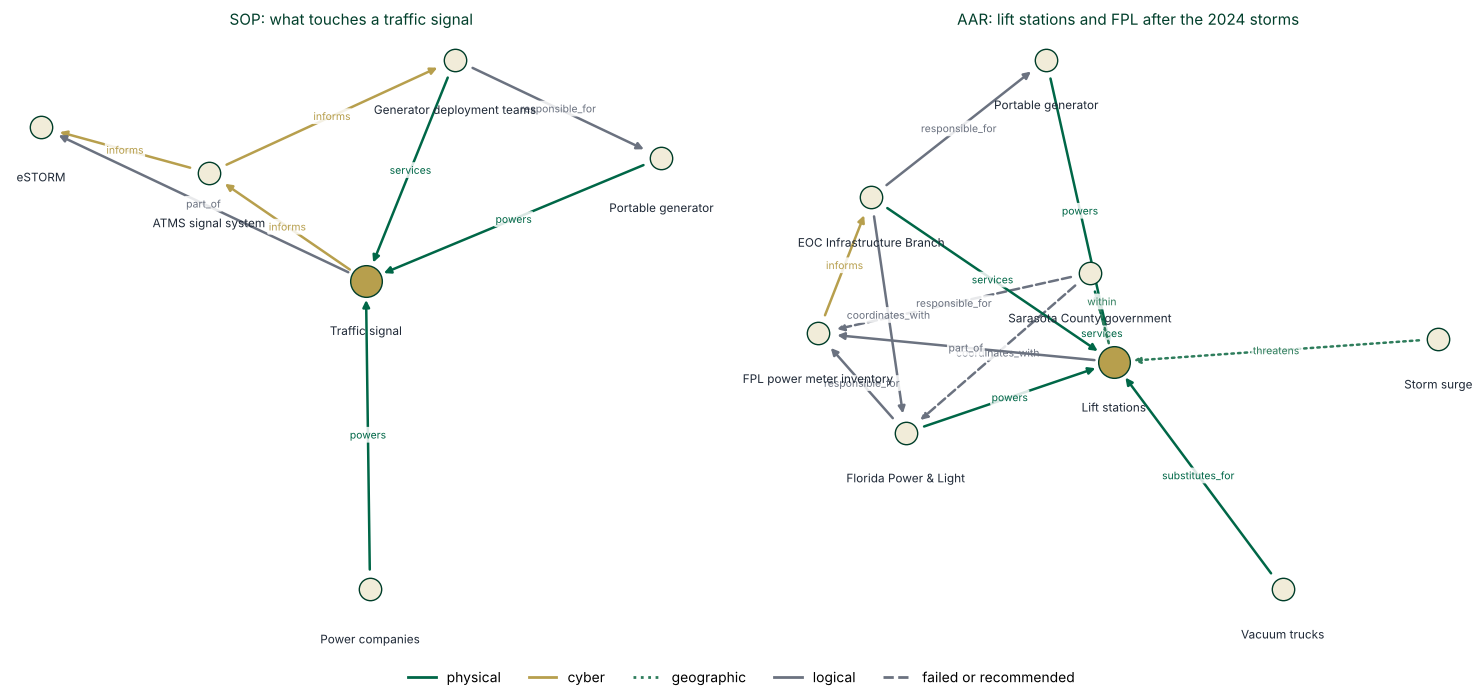

In [31]:
PAL = {"physical": "#006747", "cyber": "#B79F4D", "geographic": "#2E7D5C", "logical": "#6B7280"}
STYLE = {"physical": "-", "cyber": "-", "geographic": ":", "logical": "-"}
short = lambda n: re.sub(r"\s*\(.*?\)", "", name(n))
def neighbours(n, doc):
    return {v for _, v, d in G.out_edges(n, data=True) if d["doc"] == doc} | \
           {u for u, _, d in G.in_edges(n, data=True) if d["doc"] == doc}

def draw(ax, nodes, doc, centre, title):
    nodes = {n for n in nodes if not n.startswith("rec_")}
    pairs = collections.defaultdict(list)                   # one arrow per pair, all its relations in the label
    for u, v, d in G.edges(data=True):
        if u in nodes and v in nodes and d["doc"] == doc:
            pairs[(u, v)].append(d)
    S = nx.Graph(list(pairs))
    pos = nx.spring_layout(S, seed=3, k=1.6)
    for (u, v), ds in pairs.items():
        d = ds[0]
        ax.annotate("", xy=pos[v], xytext=pos[u],
                    arrowprops=dict(arrowstyle="-|>", color=PAL[d["cls"]], lw=1.8, shrinkA=14, shrinkB=14,
                                    linestyle="--" if d["modality"] in ("failed", "recommended") else STYLE[d["cls"]]))
        mx, my = (pos[u][0] + pos[v][0]) / 2, (pos[u][1] + pos[v][1]) / 2
        if (v, u) in pairs:                                  # two arrows between the same nodes: separate labels
            my += 0.05 if u < v else -0.05
        ax.text(mx, my, " / ".join(sorted({x["relation"] for x in ds})), fontsize=7.5, color=PAL[d["cls"]],
                ha="center", va="center", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    for n, (x, y) in pos.items():
        ax.scatter([x], [y], s=520 if n == centre else 260, color="#B79F4D" if n == centre else "#F1ECD9",
                   edgecolor="#003E2A", zorder=3)
        ax.text(x, y - 0.12, short(n), ha="center", va="top", fontsize=8.5, color="#1F2937")
    ax.set_title(title, fontsize=11, color="#003E2A"); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
draw(axes[0], {"signal"} | neighbours("signal", "SOP"), "SOP", "signal", "SOP: what touches a traffic signal")
draw(axes[1], {"lift_station", "fpl"} | neighbours("lift_station", "AAR") | neighbours("fpl", "AAR"), "AAR",
     "lift_station", "AAR: lift stations and FPL after the 2024 storms")
handles = [plt.Line2D([], [], color=c, lw=2, ls=STYLE[k], label=k) for k, c in PAL.items()] + \
          [plt.Line2D([], [], color="#6B7280", lw=2, ls="--", label="failed or recommended")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Question 3. Where are the gaps?** The AAR's `failed` and `recommended` edges are links that did not exist, or
did not work, in 2024. They are among the most useful edges in the graph, because no sensor or log records them.

In [32]:
gaps = KEPT["run A"][(KEPT["run A"].doc == "AAR") & KEPT["run A"].modality.isin(["failed", "recommended"])]
gaps.assign(subject=gaps.subject.map(name), object=gaps.object.map(name))[["page", "subject", "relation", "object", "evidence"]]

,page,subject,relation,object,evidence
3,30,Regional Law Enforcement Coordination Team,informs,EOC staff,Some EOC staff were unfamiliar with the full spectrum of RLECT support services.
10,30,EOC Emergency Services Branch,coordinates_with,Regional Law Enforcement Coordination Team,clarifying roles and responsibilities between the EOC Emergency Services Branch and Regional Law Enforceme...
11,30,EOC Emergency Services Branch,coordinates_with,Law enforcement agencies,clarifying roles and responsibilities between the EOC Emergency Services Branch and Regional Law Enforceme...
12,30,Sarasota County government,responsible_for,Barrier island closure and re-entry,The County should consider reviewing and updating the process for barrier island closure/re-entry
46,40,Third-party engineering evaluation,informs,Sarasota County government,The County should consider adopting appropriate recommendations from the third-party storm system engineer...
47,40,Portable generator,powers,Water and wastewater infrastructure,increasing generator availability for wastewater systems
48,40,Portable generator,powers,Stormwater system,pump/generator availability for the stormwater system
49,40,Pump trucks and pumps,supports,Stormwater system,pump/generator availability for the stormwater system
50,40,Sarasota County government,services,Lift stations,The County should consider opportunities to elevate lift stations’ infrastructure
51,40,Sarasota County government,coordinates_with,Florida Power & Light,The County should consider coordinating with FPL


Most of the gap edges are the AAR's recommendations: clarify roles between the Emergency Services Branch and RLECT,
review the barrier-island closure process, work with FPL on a meter inventory. Read Questions 1 and 2 again with the
handout in mind. The precondition chain for an emergency TWO runs through one funding node that three different
approvers act on. A signal depends on two power sources and on the generator teams that serve it, and through them on
ATMS status and the zone maps. That is the type-level dependency graph of the handout's section 3, recovered from
text, with a page and a quote on every edge.

## 10 · From document rules to instance edges

The documents never name an individual generator or signal, but they tell you **which keys join the records** and
**which rules create edges**. Two examples from the SOP:

- *"Reconcile between CEI check-in and FDOT NH #'s"* (page 9): the generator number is the join key between two
  logs kept by different people.
- *"Emergency and permanent repairs within the same Object ID or grouped with ¼ mile may be included in the same
  DDIR if the total cost exceeds $5,000"* (page 10): a geographic rule that turns repair records into
  `part_of` edges.

The records below are **synthetic**, generated in this cell, because the real logs are not public. The rules are
the SOP's.

In [33]:
import random, math
rng = random.Random(7)

# SYNTHETIC: 12 signals along two corridors (x, y in miles), and one damage record per signal
sig = pd.DataFrame({"signal": [f"S{i:02d}" for i in range(1, 13)],
                    "x": [0.00, 0.12, 0.30, 0.41, 0.95, 1.10, 1.62, 1.70, 2.40, 0.20, 0.31, 2.55],
                    "y": [0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.40, 0.48, 0.00]})
sig["repair_cost"] = [rng.choice([800, 1500, 2200, 3100, 4800, 6500]) for _ in range(len(sig))]

# The SOP rule: group repairs within 1/4 mile of each other (chains count), keep groups totalling at least $5,000
parent = list(range(len(sig)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for i, j in itertools.combinations(range(len(sig)), 2):
    if math.dist(sig.loc[i, ["x", "y"]], sig.loc[j, ["x", "y"]]) <= 0.25:
        parent[find(i)] = find(j)
sig["group"] = [find(i) for i in range(len(sig))]
groups = sig.groupby("group").agg(signals=("signal", " ".join), total=("repair_cost", "sum")).reset_index(drop=True)
letters = iter("ABCDEFGH")
groups["DDIR"] = [f"DDIR-{next(letters)}" if t >= 5000 else "below $5,000: no DDIR" for t in groups.total]
groups

,signals,total,DDIR
0,S01 S02 S03 S04,13300,DDIR-A
1,S05 S06,1600,"below $5,000: no DDIR"
2,S07 S08,5600,DDIR-B
3,S10 S11,5600,DDIR-C
4,S09 S12,7000,DDIR-D


In [34]:
# SYNTHETIC: the same generators, written two ways in two logs
fdot_log = pd.DataFrame({"NH": ["NH 0412", "NH 0413", "NH 0420", "NH 0431", "NH 0432"],
                         "signal": ["S01", "S03", "S05", "S07", "S09"]})
cei_log = pd.DataFrame({"generator": ["nh-412", "NH413", "NH #0420", "NH-4310", "nh 432"],
                        "checked_in": ["10/11 14:05", "10/11 15:20", "10/12 09:40", "10/12 10:15", "10/12 11:00"]})
key = lambda s: int(re.sub(r"\D", "", s))
joined = fdot_log.assign(k=fdot_log.NH.map(key)).merge(cei_log.assign(k=cei_log.generator.map(key)), on="k", how="outer")
joined["status"] = ["matched" if isinstance(a, str) and isinstance(b, str) else "check by hand"
                    for a, b in zip(joined.NH, joined.generator)]
joined.drop(columns="k")

,NH,signal,generator,checked_in,status
0,NH 0412,S01,nh-412,10/11 14:05,matched
1,NH 0413,S03,NH413,10/11 15:20,matched
2,NH 0420,S05,NH #0420,10/12 09:40,matched
3,NH 0431,S07,NaN,NaN,check by hand
4,NH 0432,S09,nh 432,10/12 11:00,matched
5,NaN,NaN,NH-4310,10/12 10:15,check by hand


Look at the first group. S01 and S04 are 0.41 miles apart, more than ¼ mile, yet they share a DDIR because each
link in the chain S01–S02–S03–S04 is shorter than ¼ mile. Does the SOP mean "every pair within ¼ mile" or "a chain
of repairs each within ¼ mile of the next"? It does not say. A rule you turn into code forces questions like this,
and the answer has to come from the DDIR team, not from you.

The typo `NH-4310` is the kind of record that a join quietly drops. The rule from the document tells you to
reconcile the two logs; the instance graph tells you which generator powers which signal only once that
reconciliation is done, and a person still has to look at what did not match.

## 11 · Plan versus reality

The SOP is a plan and the AAR is a record of what happened, so the two should not look alike. Compare the verified
edges by class and by modality.

In [35]:
kA = KEPT["run A"]
print(pd.crosstab(kA["class"], kA.doc, margins=True).to_string(), "\n")
print(pd.crosstab(kA.modality, kA.doc, margins=True).to_string())

doc         AAR  SOP  All
class                    
cyber         4   44   48
geographic    7    6   13
logical      28   50   78
physical     14    8   22
All          53  108  161 

doc          AAR  SOP  All
modality                  
failed         1    0    1
observed      39    1   40
recommended   10    4   14
required       3  103  106
All           53  108  161


**The two documents are different kinds of graph.** In the SOP, 103 of the 108 verified edges are `required`: a
plan says what must happen. In the AAR, 39 of 53 are `observed`, 10 `recommended` and 1 `failed`: a report says
what did happen and what should change. The SOP's edges are mostly cyber and logical (data into eSTORM and the
tracking sheet, approvals, preconditions). The AAR has proportionally more physical and geographic edges: surge
floods lift stations, vacuum trucks stand in for them, FPL powers the pumps.

One caution before you merge them. The SOP is FDOT District 7's (Tampa Bay), and Sarasota County lies in FDOT
District 1. Because the entities are types, the two documents share a schema (generators, EOCs, power companies),
but nothing named in one is the same physical object as anything in the other. A combined graph compares practice;
it is not one network.

## 12 · Your turn

1. **Label one page yourself.** Take SOP page 9 (no gold set yet). Read `lab8_files/schema.md`, write 10 or more
   edges in the format of `gold_edges.csv`, then score run A against your labels with `prf()`. Swap labels with a
   classmate and score yourselves against each other: that number is the ceiling for any model.
2. **Make your own run.** Send the prompt for SOP page 7 to Claude (section 6b), paste the answer, and run sections 7
   and 8 again. Which of your edges fail the checks, and why?
3. **Change one rule.** Drop rule 2 (the implied actor) from `schema.md` and count how many gold edges disappear.
   What does District 7's own role in its procedure look like without it?
4. **Find a missing edge.** The AAR says Sarasota County learned during Milton that FPL already keeps a meter
   inventory for lift stations and booster pumps (page 39). Which edge in the SOP plays the same role for traffic
   signals, and is it there?
5. **Extend the table.** Add the SOP acronyms the entity table does not cover, rerun the baseline, and see whether
   its precision or its recall moves.

## Fit card: building a graph from documents with a language model

| | |
| --- | --- |
| **Idea in one sentence** | Fix a schema and an entity table, let a language model read each page into typed edges with quotes, and keep only the edges that pass automatic checks and agree with a hand-labeled sample. |
| **Why it works (the logic)** | The schema turns open reading into a choice among a dozen relations; the quote turns each edge into a claim anyone can check against the page. |
| **Fits these tasks** | Dependency graphs from SOPs, AARs, work orders, contracts and manuals; responsibility matrices; candidate edges for a GNN. Leverage labels: extraction, classification, judgment (the checks). |
| **Needs this data** | The documents, an entity table with approved aliases, 50–100 hand-labeled edges on a few pages, and the people who run the system to review the strongest new edges. |
| **Breaks when** | Tables are read as plain text; captions and columns interleave; the schema is vague; names are merged by fuzzy matching; recommendations are treated as links that exist; nobody scores against a gold set. |
| **Keep the classical method when** | The edges are already in a table (parse it), the documents are few enough to read (label them by hand), or the link lives in a record with a key (join the records). |

## Check yourself

1. A district asks you to build the responsibility graph for its hurricane SOP, and its responsibility-matrix
   appendix turns out to be blank in the copy you were given. What do you do first, and why not start with a model?
2. A model run reports 0.9 precision on the gold pages, but a second run with the same prompt agrees with the first
   on only 60% of its edges. Which number would you report to the agency, and what would you change?
3. The AAR's recommendation 54 says the County should develop a power meter inventory with FPL by June 2026. Should
   that be an edge in a graph you hand to a GNN today? With which modality, and why does it matter?

**Answer notes.** (1) Ask the district for the matrix. A table they already maintain is cheaper and more reliable
than any extraction, and the prose is the fallback. (2) Report both. High precision with low agreement means each
run finds a different subset of true edges; keep the edges found by both runs, or take the union and verify it,
and fix the prompt where the runs disagree. (3) Not as a working dependency. It is a recommended edge: useful as a
gap to close and as a question for FPL, but a model that treats it as an existing link will assume information that
the County did not have during Milton.

*Sources: FDOT District 7, Traffic Signals SOP Reference Guide, v1.5, June 2025; Sarasota County Emergency
Services, 2024 Hurricane Season After-Action Report, May 2025; S. M. Rinaldi, J. P. Peerenboom and T. K. Kelly,
"Identifying, understanding, and analyzing critical infrastructure interdependencies," IEEE Control Systems
Magazine 21(6), 2001.*